# How face morphing works
A visual tutorial for curious beginners. **Morphing changes both shape and color.** Think of two photographs printed on stretchy sheets: first line up their facial features, then mix their colors.

You can read the explanations and pictures without understanding every line of Python. Code cells implement each step; run them from top to bottom.

Adapted from [a-tabaza/face-morphing](https://github.com/a-tabaza/face-morphing), which credits [Azmarie/Face-Morphing](https://github.com/Azmarie/Face-Morphing/). The original files and history are available in Git.

## Road map
1. Set up and choose two pictures.
2. Put both pictures on a matching canvas.
3. Find corresponding facial landmarks.
4. Connect the landmarks into triangles.
5. Move both faces toward the same intermediate shape.
6. Blend their colors and compare with a plain cross-fade.
7. Export a short animation and try your own examples.

## 1. Open and run locally
From Terminal:
```bash
cd ~/Development/face-morphing-tutorial
python -m jupyter lab face_morphing.ipynb
```
Use a Python environment containing `numpy`, `opencv-python`, `dlib`, `Pillow`, `matplotlib`, `onnxruntime`, and Jupyter. If needed, install them **in that environment**; dlib installation may require build tools. There is no Google Drive mounting step. The landmark predictor and sample photographs are included in the original repository. The ear/neck extension uses an additional ONNX model saved in `models/` (download instructions in the README).

Start Jupyter in this folder, select its Python kernel, then choose **Run → Run All Cells**. Outputs go into `tutorial_output/`; the original sample GIFs are preserved.


In [153]:
from pathlib import Path
import math
import cv2
import dlib
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Image as DisplayImage

ROOT = Path.cwd()
INPUT_DIR = ROOT / "input"
OUTPUT_DIR = ROOT / "output"
OUTPUT_DIR.mkdir(exist_ok=True)

MODEL = ROOT / "models"

PREDICTOR_PATH = MODEL / "shape_predictor_68_face_landmarks.dat"
if not PREDICTOR_PATH.exists():
    raise FileNotFoundError("Start Jupyter inside the face-morphing-tutorial folder.")

# Change these filenames to choose a different pair.
IMAGE_A = INPUT_DIR / "BM51_PMS7_01.png"
IMAGE_B = INPUT_DIR / "BM51_PMS7_11.png" 
CANVAS_SIZE = 400
FRAME_COUNT = 21
FRAME_DURATION_MS = 100
SHOW_MESH_IN_GIF = False
print("Working folder:", ROOT)


Working folder: /Users/cyrusyang/Development/face-morphing-tutorial


## 2. Prepare the two photographs
Use one visible, roughly frontal face per picture. Similar pose and framing help corresponding features match.

We resize each image to cover a square canvas, preserving its aspect ratio, then crop the excess around the center. **Matching image size does not automatically align the eyes or correct head rotation.** We inspect the result before continuing.

OpenCV loads colors in BGR order; we convert to RGB when displaying them.


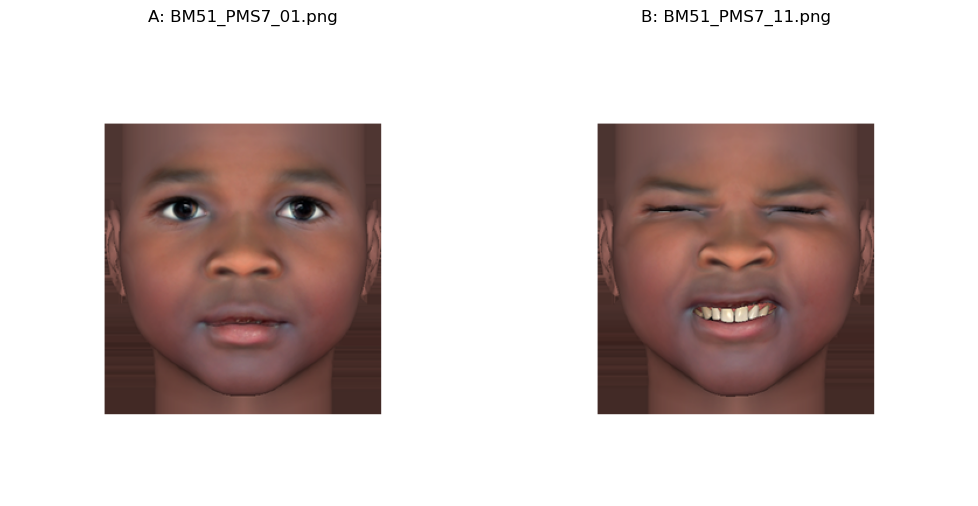

In [154]:
def load_on_canvas(filename, side=CANVAS_SIZE):
    image = cv2.imread(str(ROOT / filename))
    if image is None:
        raise FileNotFoundError(f"Could not read {filename}")
    h, w = image.shape[:2]
    scale = side / min(h, w)
    image = cv2.resize(image, (math.ceil(w * scale), math.ceil(h * scale)),
                       interpolation=cv2.INTER_AREA if scale < 1 else cv2.INTER_LINEAR)
    h, w = image.shape[:2]
    top, left = (h - side) // 2, (w - side) // 2
    return image[top:top + side, left:left + side].copy()
    
def show_images(images, titles, figsize=None):
    fig, axes = plt.subplots(1, len(images), figsize=figsize or (5 * len(images), 5))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

image_a = load_on_canvas(IMAGE_A)
image_b = load_on_canvas(IMAGE_B)
show_images([image_a, image_b], [f"A: {Path(IMAGE_A).name}", f"B: {Path(IMAGE_B).name}"])


## 3. Give matching features matching numbers

Build the correspondence in three stages, then compare both images at each stage.

### 3.1 Default facial landmarks and image-boundary points
The dlib model predicts **68 landmarks** around the jaw, eyebrows, nose, eyes, and mouth. Landmark number *i* has the same anatomical role in both photographs.

This correspondence tells us which part of face A should move toward which part of face B. We also add **eight boundary points** to cover the surrounding picture, giving 76 points in total.

These are predictions, not perfect measurements. Check the dots: errors around eyes or mouth can create noticeable artifacts.


In [155]:
detector = dlib.get_frontal_face_detector()
predictor = dlib.shape_predictor(str(PREDICTOR_PATH))

def landmarks_with_boundary(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    faces = detector(gray, 1)
    if len(faces) != 1:
        raise ValueError(f"Expected one face; detected {len(faces)}. Try another crop/photo.")
    shape = predictor(gray, faces[0])
    points = np.array([(shape.part(i).x, shape.part(i).y) for i in range(68)], dtype=np.float32)
    h, w = image.shape[:2]
    if np.any(points < 0) or np.any(points[:, 0] >= w) or np.any(points[:, 1] >= h):
        raise ValueError("A predicted landmark is outside the canvas; use a better-framed photo.")
    boundary = np.array([(0, 0), ((w-1)/2, 0), (w-1, 0),
                         (w-1, (h-1)/2), (w-1, h-1), ((w-1)/2, h-1),
                         (0, h-1), (0, (h-1)/2)], dtype=np.float32)
    return np.vstack([points, boundary])

points_a = landmarks_with_boundary(image_a)
points_b = landmarks_with_boundary(image_b)
print('Stage 3.1: 76 points per image. See the comparison after section 3.3.')


Stage 3.1: 76 points per image. See the comparison after section 3.3.


### 3.2 Follow the visible hairline, rather than guessing forehead positions

**Semantic edge detection.** The local BiSeNet face parser separates skin from hair. We trace the upper skin boundary wherever hair is immediately adjacent, above the eyebrows. This identifies the **skin–hair interface**, rather than every intensity edge that a generic edge detector might also find in wrinkles, shadows, or hair texture. The trace is restricted to a frontal search window based on the brows; it is not the entire scalp outline.

1. Predict skin and hair pixels separately in **each image**.
2. Keep the largest skin region and locate its upper edge within two pixels of predicted hair.
3. Retain the longest continuous frontal segment, without connecting across missing columns or hidden regions.
4. Sample **eight ordered points H1–H8** at evenly spaced arc-length fractions, from image left to right, and connect them visually. These eight points replace the old offset anchors in the downstream mesh.

With a usable contour in both photographs: **68 facial + 8 hairline + 8 canvas = 84 points**. Unlike the previous shared offsets, the hairline points follow each photograph's own geometry. Equal arc-length fractions provide approximate correspondences—not guaranteed identical anatomical locations.

The final visualization shows the detected contour and H1–H8 in **magenta**, with the old geometric points as gray crosses. If either hairline is not recovered, the notebook omits hairline controls from both meshes and reports the issue instead of inventing a boundary. Bald heads, bangs, cropped hairlines, strong head rotation, and segmentation errors need manual review; an occluding hair edge need not be the true hairline.

This improves placement relative to a visible image boundary; it does not by itself prove more realistic morphs or preserve experimental validity. Section 3.3 uses the same local parser for ears and neck.

Source: [BiSeNet face parsing](https://github.com/yakhyo/face-parsing). The contour extraction and point sampling are custom tutorial code.

**Also cover the top of the hair, not only the forehead.** We now trace a second boundary: **hair against background**. Up to nine extra controls **T1–T9** sample its visible upper outline, ordered left to right by relative horizontal position across the hair region. These move with each image's hair silhouette instead of leaving the top of the head controlled mainly by distant canvas corners.

- **Magenta H points:** the inner skin–hair boundary.
- **Blue T points and contour:** the outer hair–background boundary.
- The triangle mesh between the two contours also warps the intervening hair pixels. There is no special hair synthesis or texture matching.
- Controls enter the downstream morph by default (`USE_HAIR_OUTLINE_CONTROLS = True`). Only matching names visible in both images are used; near-duplicates are skipped.
- Clipped top-of-head pixels are not a real detected boundary. Missing contour segments remain gaps; use a wider-framed image if the hair touches the crop. Long hair, hats, very different hairstyles, and rotation may invalidate these approximate correspondences.

This targets positional ghosting from mismatched silhouettes. Differences in hair texture and occlusion can still ghost during color blending; adding controls does not guarantee artifact-free stimuli.

In [156]:
import onnxruntime as ort
import warnings
import hashlib

PARSING_MODEL = MODEL / 'face_parsing_resnet18.onnx'
PARSING_URL = 'https://github.com/yakhyo/face-parsing/releases/download/weights/resnet18.onnx'
if not PARSING_MODEL.exists():
    raise FileNotFoundError(f'Download {PARSING_URL} into {PARSING_MODEL}; see README.')


session = ort.InferenceSession(str(PARSING_MODEL), providers=['CPUExecutionProvider'])

def parse_face_regions(image):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    rgb = cv2.resize(rgb, (512, 512), interpolation=cv2.INTER_LINEAR)
    tensor = rgb.astype(np.float32) / 255.0
    tensor = (tensor - np.array([0.485, 0.456, 0.406], np.float32)) / np.array([0.229, 0.224, 0.225], np.float32)
    tensor = np.ascontiguousarray(tensor.transpose(2, 0, 1)[None])
    logits = session.run(None, {session.get_inputs()[0].name: tensor})[0]
    labels = logits[0].argmax(axis=0).astype(np.uint8)
    return cv2.resize(labels, (image.shape[1], image.shape[0]), interpolation=cv2.INTER_NEAREST)


FOREHEAD_ROW_CONFIG = ((0.10, -0.03), (0.13, -0.05),
                       (0.15, -0.08), (0.33, -0.12))

def forehead_controls(reference_landmarks, image_shape):
    x, y, w, h = cv2.boundingRect(np.round(reference_landmarks).astype(np.int32))
    controls = []
    for inset, height_offset in FOREHEAD_ROW_CONFIG:
        dx, dy = int(w * inset), int(h * height_offset)
        controls.extend([(x + dx, y + dy), (x + w - dx, y + dy)])
    controls = np.asarray(controls, dtype=np.float32)
    image_h, image_w = image_shape[:2]
    controls[:, 0] = np.clip(controls[:, 0], 1, image_w - 1)
    controls[:, 1] = np.clip(controls[:, 1], 1, image_h - 1)
    return controls


base_points_a = landmarks_with_boundary(image_a)
base_points_b = landmarks_with_boundary(image_b)
USE_FOREHEAD_CONTROLS = True
labels_a, labels_b = parse_face_regions(image_a), parse_face_regions(image_b)

# Keep the former geometric anchors for visual comparison only.
legacy_forehead_points = forehead_controls((base_points_a[:68]+base_points_b[:68])/2, image_a.shape)

def trace_visible_hairline(labels, facial_points):
    # Largest skin component excludes isolated false-positive patches.
    count, cc, stats, _ = cv2.connectedComponentsWithStats((labels == 1).astype(np.uint8), 8)
    if count < 2:
        return np.empty((0, 2), np.float32), 'No usable skin region.'
    skin = cc == (1 + np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    hair_nearby = cv2.dilate((labels == 17).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    face_width = float(np.ptp(facial_points[:17, 0]))
    x0 = max(1, int(facial_points[17:27, 0].min() - .15*face_width))
    x1 = min(labels.shape[1]-2, int(facial_points[17:27, 0].max() + .15*face_width))
    brow_limit = int(facial_points[17:27, 1].max())
    candidate = skin & hair_nearby
    # Ignore beard and lower-face boundaries; find the top skin edge at each column.
    runs, run = [], []
    for x in range(x0, x1+1):
        ys = np.flatnonzero(candidate[:brow_limit, x])
        if len(ys):
            run.append((x, int(ys[0])))
        elif run:
            runs.append(run); run = []
    if run:
        runs.append(run)
    if not runs:
        return np.empty((0, 2), np.float32), 'No continuous visible skin–hair interface above the brows.'
    curve = np.asarray(max(runs, key=len), np.float32)
    if len(curve) < max(20, .35*face_width):
        return np.empty((0, 2), np.float32), 'Visible interface too short; inspect hair, crop, and segmentation.'
    return curve, 'Detected frontal skin–hair interface; sideburns and hidden contours excluded.'

def sample_hairline(curve, count=8):
    length = np.r_[0, np.cumsum(np.linalg.norm(np.diff(curve, axis=0), axis=1))]
    targets = np.linspace(.03, .97, count) * length[-1]
    return np.column_stack([np.interp(targets, length, curve[:, d]) for d in range(2)]).astype(np.float32)

hairline_a, hairline_status_a = trace_visible_hairline(labels_a, base_points_a[:68])
hairline_b, hairline_status_b = trace_visible_hairline(labels_b, base_points_b[:68])
hairline_pair_available = len(hairline_a) > 0 and len(hairline_b) > 0
forehead_points_a = sample_hairline(hairline_a) if hairline_pair_available else np.empty((0, 2), np.float32)
forehead_points_b = sample_hairline(hairline_b) if hairline_pair_available else np.empty((0, 2), np.float32)
points_a = np.vstack([base_points_a[:68], forehead_points_a, base_points_a[68:]]) if USE_FOREHEAD_CONTROLS else base_points_a.copy()
points_b = np.vstack([base_points_b[:68], forehead_points_b, base_points_b[68:]]) if USE_FOREHEAD_CONTROLS else base_points_b.copy()
print('A:', hairline_status_a)
print('B:', hairline_status_b)
if not hairline_pair_available:
    print('Omitting hairline controls from BOTH images: no guessed fallback.')
print(f'Stage 3.2: {len(points_a)} points per image; old offset points are comparison-only.')


# Outer hair silhouette: a second contour, distinct from the skin–hair boundary.
USE_HAIR_OUTLINE_CONTROLS = True
HAIR_OUTLINE_FRACTIONS = np.linspace(0.06, 0.94, 9)

def outer_hair_controls(labels, face_points):
    count, component, stats, _ = cv2.connectedComponentsWithStats((labels == 17).astype(np.uint8), 8)
    if count < 2:
        return {}, np.empty((0, 2), np.float32), 'No usable hair region.'
    mask = component == (1 + np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    ys, xs = np.where(mask)
    near_background = cv2.dilate((labels == 0).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    brow_limit = int(face_points[17:27, 1].min())
    contour = []
    for x in range(int(xs.min()), int(xs.max())+1):
        rows = np.flatnonzero(mask[:, x])
        y = int(rows[0]) if len(rows) else -1
        valid = 1 < y < brow_limit and 1 < x < labels.shape[1]-2 and near_background[y, x]
        contour.append((x, float(y) if valid else np.nan))
    contour = np.asarray(contour, np.float32)
    result = {}
    for i, fraction in enumerate(HAIR_OUTLINE_FRACTIONS, 1):
        x = int(round(xs.min() + fraction*(xs.max()-xs.min())))
        y = contour[x-int(xs.min()), 1]
        if np.isfinite(y):
            result[f'T{i}'] = (float(x), float(y))
    message = 'Visible upper hair–background boundary sampled.'
    if ys.min() <= 1:
        message += ' Hair touches the top crop: clipped portions are not treated as a detected contour.'
    return result, contour, message

hair_controls_a, hair_outline_a, hair_outline_status_a = outer_hair_controls(labels_a, base_points_a[:68])
hair_controls_b, hair_outline_b, hair_outline_status_b = outer_hair_controls(labels_b, base_points_b[:68])
hair_point_names = []
if USE_HAIR_OUTLINE_CONTROLS:
    for name in hair_controls_a:
        if name not in hair_controls_b:
            continue
        a, b = np.asarray(hair_controls_a[name]), np.asarray(hair_controls_b[name])
        if min(np.linalg.norm(points_a-a, axis=1).min(), np.linalg.norm(points_b-b, axis=1).min(),
               np.linalg.norm((points_a+points_b)/2-(a+b)/2, axis=1).min()) < 2:
            continue
        points_a = np.vstack([points_a[:-8], a, points_a[-8:]]).astype(np.float32)
        points_b = np.vstack([points_b[:-8], b, points_b[-8:]]).astype(np.float32)
        hair_point_names.append(name)
stage2_points_a, stage2_points_b = points_a.copy(), points_b.copy()
print('Outer hair A:', hair_outline_status_a)
print('Outer hair B:', hair_outline_status_b)
print(f'Added {len(hair_point_names)} paired outer-hair controls: {hair_point_names}')


A: Visible interface too short; inspect hair, crop, and segmentation.
B: Detected frontal skin–hair interface; sideburns and hidden contours excluded.
Omitting hairline controls from BOTH images: no guessed fallback.
Stage 3.2: 76 points per image; old offset points are comparison-only.
Outer hair A: Visible upper hair–background boundary sampled. Hair touches the top crop: clipped portions are not treated as a detected contour.
Outer hair B: Visible upper hair–background boundary sampled. Hair touches the top crop: clipped portions are not treated as a detected contour.
Added 4 paired outer-hair controls: ['T1', 'T7', 'T8', 'T9']


### 3.3 Extend to visible ears and neck with face parsing

The 68-point detector stops around the face. To locate **visible ear and neck regions**, we add a different model: **BiSeNet face parsing**. It labels pixels by facial part rather than returning a few object boxes. Inference runs locally on the two cropped images; no photos are uploaded.

**Three different kinds of points now coexist:**
- **Detected landmarks:** the original 68 anatomically indexed facial points.
- **Constructed anchors:** eight canvas points.
- **Segmentation-derived controls:** hairline points plus samples from predicted ear/neck outlines. These are approximate contour correspondences, not validated anatomical landmarks.

**How regions become corresponding points:**
1. Predict a semantic label for each pixel. Use the ear classes (7 and 8) and neck class (14); do not include earrings or necklaces as neck/ear skin.
2. Keep the largest usable component for each visible ear and for the neck. Name ear sides by **image left/right**, avoiding ambiguity about anatomical left/right.
3. Place three outer-contour controls at 15%, 50%, and 85% of each ear's visible height: **EL1–EL3** and **ER1–ER3**.
4. At 25%, 50%, and 75% of the neck's usable visible height (rows with neck pixels on both sides of the face center), take its left and right edges: **NL1–NL3** and **NR1–NR3**.
5. Keep only point names supported in **both** images, in identical order; skip near-duplicate vertices. With both ears and the neck detected, up to **12 extra controls** give up to **105 total points** when all eight hairline and nine outer-hair controls are available.

**Inspect before interpreting:** ear shape, hair occlusion, collars, and unequal crops can make corresponding fractions describe different physical locations. This is a useful prototype, not proof of anatomical correspondence or better realism. A missing region is omitted from both meshes, not filled with invented points. A cropped neck triggers a message; the algorithm cannot recover skin outside the picture. Use similarly framed images with the needed regions visible, and check the overlays. Optional `REVIEWED_POINT_OVERRIDES` lets you correct existing detected controls explicitly.

`USE_EAR_NECK_CONTROLS` determines whether the paired controls enter the subsequent morph. The shaded overlay shows the **predicted regions**; it does not remove the background. Your experimental face-only masking code would also need a deliberate change to its retained region if you want its final output to include ears/neck. That separate experimental notebook is unchanged.

**Model and reproducibility:** the downloaded ResNet18 ONNX weights (~51 MB) are stored in `models/`; `onnxruntime` is required. The result JSON records filenames, coordinates, reviewed overrides, crop notes, and the model SHA-256. See the README for download instructions.

Sources: [BiSeNet face-parsing model and weights](https://github.com/yakhyo/face-parsing), [inference preprocessing](https://github.com/yakhyo/face-parsing/blob/main/onnx_inference.py), [class labels](https://github.com/yakhyo/face-parsing/blob/main/utils/common.py). The point-sampling scheme is an extension written for this tutorial, not a landmark detector provided by that repository.

In [157]:
USE_EAR_NECK_CONTROLS = True
REVIEWED_POINT_OVERRIDES = {'A': {}, 'B': {}}

def largest_region(mask):
    count, component, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), 8)
    if count < 2:
        return None
    index = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    if stats[index, cv2.CC_STAT_AREA] < 30:
        return None
    return component == index

def extract_region_controls(labels, face_landmarks):
    controls, masks, messages = {}, {}, []
    mid_x = float(np.median(face_landmarks[:, 0]))
    # Combine the model's two ear classes, then use image-side naming to avoid
    # confusing the subject's anatomical left with the viewer's left.
    for side in ['left', 'right']:
        ear = np.isin(labels, [7, 8])
        cols = np.arange(labels.shape[1])[None, :]
        ear &= cols < mid_x if side == 'left' else cols >= mid_x
        mask = largest_region(ear)
        region = 'ear_image_' + side
        if mask is None:
            messages.append(region + ': missing or too small; no points invented')
            continue
        masks[region] = mask
        ys, xs = np.where(mask)
        if xs.min() == 0 or xs.max() == labels.shape[1] - 1 or ys.min() == 0 or ys.max() == labels.shape[0] - 1:
            messages.append(region + ': touches crop boundary; review visibility')
        # Three points down the visible OUTER ear contour, not helix/tragus landmarks.
        for number, fraction in enumerate([0.15, 0.50, 0.85], 1):
            target_y = ys.min() + fraction * (ys.max() - ys.min())
            row = np.unique(ys)[np.argmin(abs(np.unique(ys) - target_y))]
            xx = xs[ys == row]
            x = xx.min() if side == 'left' else xx.max()
            controls[f'{region}_{number}'] = (float(x), float(row))

    mask = largest_region(labels == 14)  # neck; class 15 is necklace, not neck
    if mask is None:
        messages.append('neck: missing or too small; no points invented')
    else:
        masks['neck'] = mask
        ys, xs = np.where(mask)
        if ys.max() == labels.shape[0] - 1:
            messages.append('neck: cropped at bottom; points describe only the visible portion')
        # Only sample rows with neck pixels on both sides of the face center.
        # Near the jaw, the neck may appear as just one thin side sliver.
        valid_rows = np.array([row for row in np.unique(ys)
                               if xs[ys == row].min() < mid_x - 2
                               and xs[ys == row].max() > mid_x + 2])
        if len(valid_rows) < 6:
            messages.append('neck: insufficient bilateral visible extent; no points added')
            return controls, masks, messages
        for number, fraction in enumerate([0.25, 0.50, 0.75], 1):
            target_y = valid_rows.min() + fraction * (valid_rows.max() - valid_rows.min())
            row = valid_rows[np.argmin(abs(valid_rows - target_y))]
            xx = xs[ys == row]
            controls[f'neck_left_{number}'] = (float(xx.min()), float(row))
            controls[f'neck_right_{number}'] = (float(xx.max()), float(row))
    return controls, masks, messages

controls_a, masks_a, warnings_a = extract_region_controls(labels_a, base_points_a[:68])
controls_b, masks_b, warnings_b = extract_region_controls(labels_b, base_points_b[:68])
for controls, overrides in [(controls_a, REVIEWED_POINT_OVERRIDES['A']),
                             (controls_b, REVIEWED_POINT_OVERRIDES['B'])]:
    for name, xy in overrides.items():
        if name not in controls:
            raise ValueError('Review existing detections only; missing region: ' + name)
        x, y = map(float, xy)
        if not (0 <= x < image_a.shape[1] and 0 <= y < image_a.shape[0]):
            raise ValueError('Override outside canvas: ' + name)
        controls[name] = (x, y)

# Keep matching point names in exactly the same order in both pictures.
# Skip an entire region if it is not detected in BOTH images.
common_names = []
for region in ['ear_image_left', 'ear_image_right', 'neck']:
    names = [name for name in controls_a if name.startswith(region + '_')]
    if names and all(name in controls_b for name in names):
        common_names.extend(names)
    else:
        print(f'Omitting unmatched region from morph: {region}')

# Preserve sections 3.1/3.2 even when rerunning this cell.
def stage_points(base, forehead, include_forehead):
    return (np.vstack([base[:68], forehead, base[68:]])
            if include_forehead else base.copy())

points_a = stage2_points_a.copy()
points_b = stage2_points_b.copy()
accepted_names = []
if USE_EAR_NECK_CONTROLS:
    for name in common_names:
        a, b = np.asarray(controls_a[name]), np.asarray(controls_b[name])
        # Avoid duplicate/near-identical vertices that can break triangulation.
        distances = [np.min(np.linalg.norm(points_a - a, axis=1)),
                     np.min(np.linalg.norm(points_b - b, axis=1)),
                     np.min(np.linalg.norm((points_a + points_b)/2 - (a+b)/2, axis=1))]
        if min(distances) < 2.0:
            print('Skipping near-duplicate control in both images:', name)
            continue
        points_a = np.vstack([points_a[:-8], a, points_a[-8:]]).astype(np.float32)
        points_b = np.vstack([points_b[:-8], b, points_b[-8:]]).astype(np.float32)
        accepted_names.append(name)

for prefix, messages in [('A', warnings_a), ('B', warnings_b)]:
    for message in messages:
        print(f'Review {prefix}: {message}')
print(f'{len(accepted_names)} matched ear/neck controls added; {len(points_a)} total points per image.')
print('Accepted point order:', accepted_names)
print('Review the mask overlays and point correspondence below before treating these as experimental stimuli.')

# Save derived coordinates and raw segmentation labels for reproducibility.
import json
cv2.imwrite(str(OUTPUT_DIR / 'parsing_labels_A.png'), labels_a)
cv2.imwrite(str(OUTPUT_DIR / 'parsing_labels_B.png'), labels_b)
(OUTPUT_DIR / 'extended_landmarks.json').write_text(json.dumps({
    'images': [str(IMAGE_A), str(IMAGE_B)], 'canvas_size': CANVAS_SIZE,
    'parser_url': PARSING_URL, 'parser_sha256': hashlib.sha256(PARSING_MODEL.read_bytes()).hexdigest(),
    'matched_region_names': accepted_names, 'region_controls_A': controls_a,
    'region_controls_B': controls_b, 'points_A': points_a.tolist(), 'points_B': points_b.tolist(),
    'reviewed_overrides': REVIEWED_POINT_OVERRIDES,
    'hairline_A': hairline_a.tolist(), 'hairline_B': hairline_b.tolist(),
    'hairline_controls_A': forehead_points_a.tolist(), 'hairline_controls_B': forehead_points_b.tolist(),
    'hairline_status': [hairline_status_a, hairline_status_b],
    'outer_hair_control_names': hair_point_names,
    'outer_hair_controls_A': hair_controls_a, 'outer_hair_controls_B': hair_controls_b,
    'outer_hair_status': [hair_outline_status_a, hair_outline_status_b],
    'notes': warnings_a + warnings_b}, indent=2))


12 matched ear/neck controls added; 92 total points per image.
Accepted point order: ['ear_image_left_1', 'ear_image_left_2', 'ear_image_left_3', 'ear_image_right_1', 'ear_image_right_2', 'ear_image_right_3', 'neck_left_1', 'neck_right_1', 'neck_left_2', 'neck_right_2', 'neck_left_3', 'neck_right_3']
Review the mask overlays and point correspondence below before treating these as experimental stimuli.


18159

**Compare the three stages on both images**

Rows show the additions; columns hold the same two photographs. Orange and green shading makes the model’s ear/neck predictions inspectable. EL/ER and NL/NR identify paired contour samples; magenta points follow the detected skin–hair boundary; gray crosses show the old offset method.

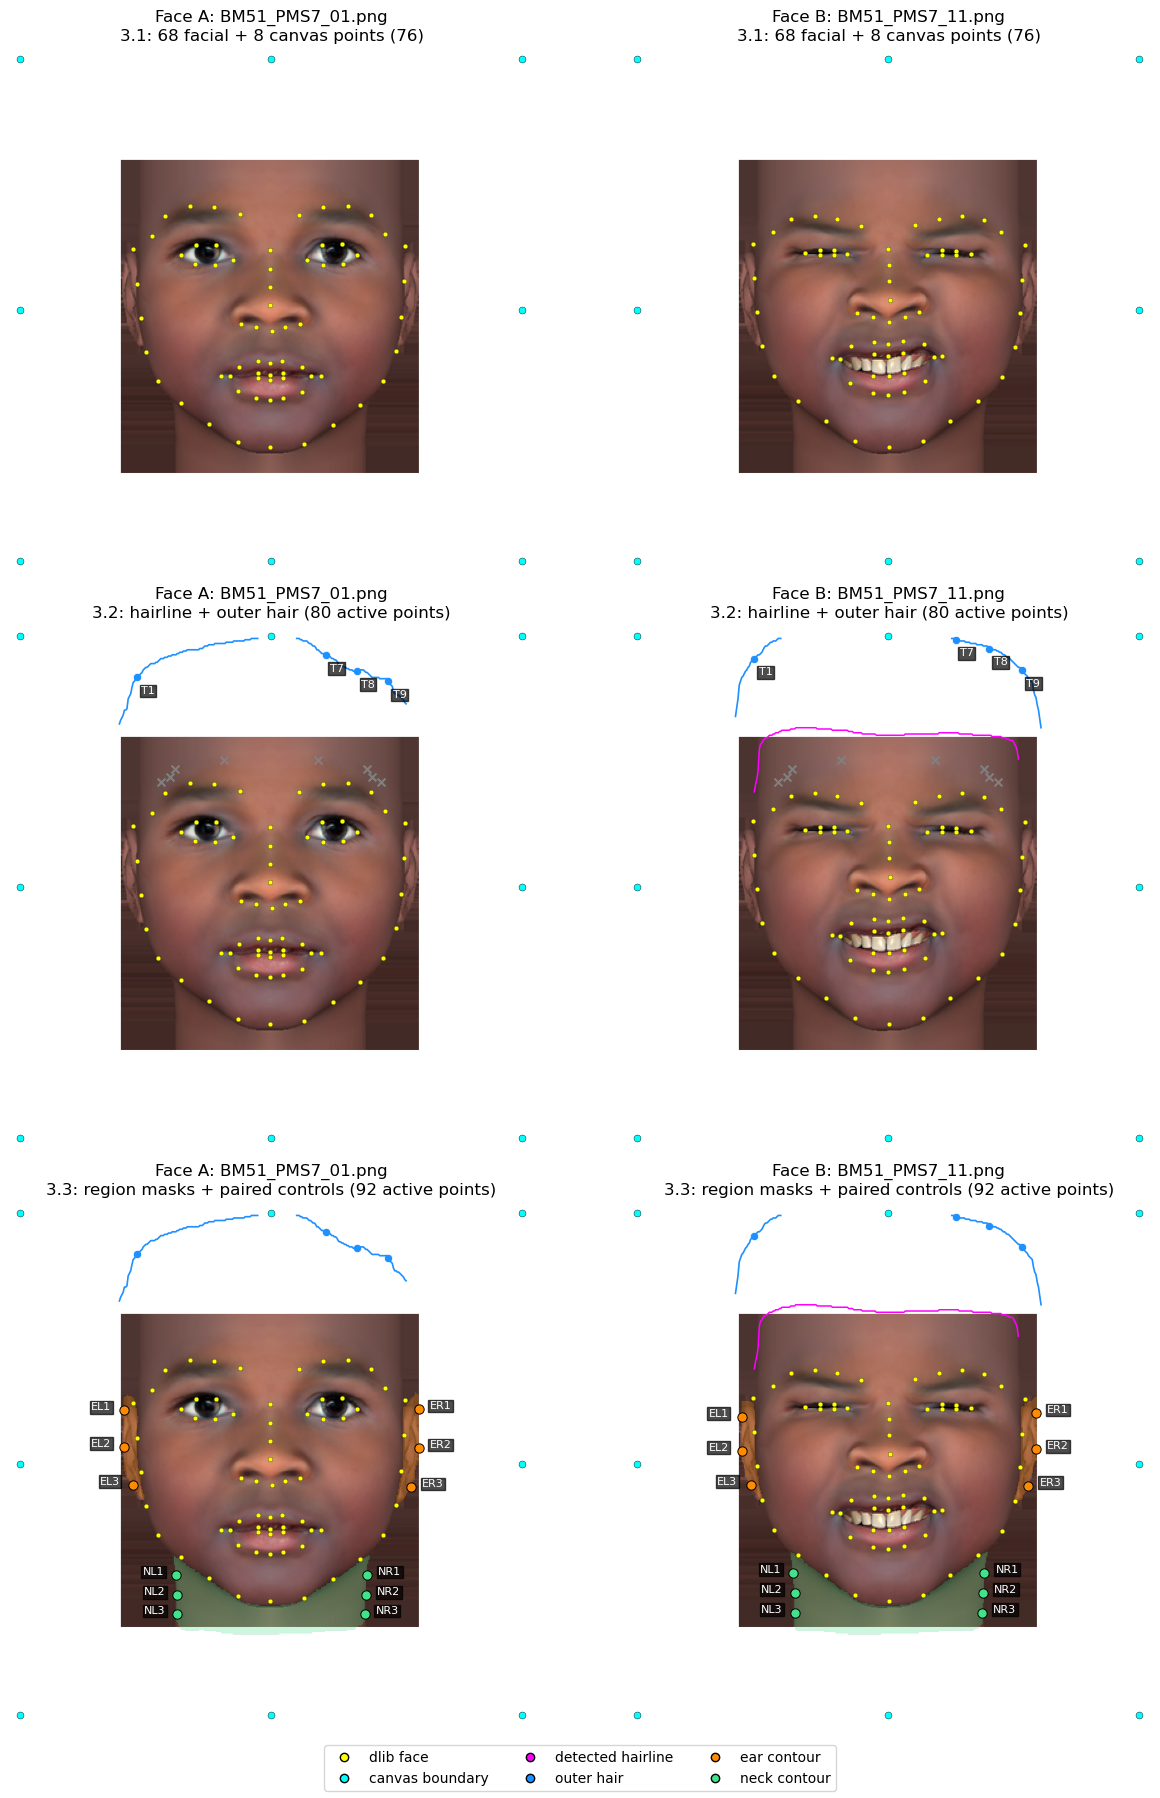

Saved side-by-side comparison: /Users/cyrusyang/Development/face-morphing-tutorial/output/landmark_stages_comparison.png


In [158]:
# Final comparison: same columns/images at each stage; fixed limits make changes comparable.
from matplotlib.lines import Line2D
REGION_COLORS = {'ear_image_left': '#ff8c00', 'ear_image_right': '#ff8c00', 'neck': '#42e28a'}
fig, axes = plt.subplots(3, 2, figsize=(13, 18))
for col, (image, base, controls, masks, title) in enumerate([
        (image_a, base_points_a, controls_a, masks_a, f"Face A: {Path(IMAGE_A).name}"),
        (image_b, base_points_b, controls_b, masks_b, f"Face B: {Path(IMAGE_B).name}")]):
    rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    for row in range(3):
        ax = axes[row, col]
        ax.imshow(rgb)
        if row == 2:
            overlay = np.zeros((*rgb.shape[:2], 4), dtype=np.float32)
            from matplotlib.colors import to_rgb
            for name, mask in masks.items():
                overlay[mask, :3] = to_rgb(REGION_COLORS[name])
                overlay[mask, 3] = 0.27
            ax.imshow(overlay)
        ax.scatter(base[:68, 0], base[:68, 1], s=12, c='yellow', edgecolors='black', linewidths=0.2)
        ax.scatter(base[68:, 0], base[68:, 1], s=25, c='cyan', edgecolors='black', linewidths=0.3)
        forehead_points = forehead_points_a if col == 0 else forehead_points_b
        curve = hairline_a if col == 0 else hairline_b
        if row >= 1:
            hair_curve = hair_outline_a if col == 0 else hair_outline_b
            hair_controls = hair_controls_a if col == 0 else hair_controls_b
            if len(hair_curve):
                ax.plot(hair_curve[:, 0], hair_curve[:, 1], color='dodgerblue', linewidth=1.2)
            for name in hair_point_names:
                tx, ty = hair_controls[name]
                ax.scatter([tx], [ty], s=35, c='dodgerblue', edgecolors='white', linewidths=.5)
                if row == 1:
                    ax.annotate(name, (tx, ty), xytext=(3, -12), textcoords='offset points', fontsize=8,
                                color='white', bbox=dict(facecolor='black', alpha=.7, pad=1))
            if len(curve):
                ax.plot(curve[:, 0], curve[:, 1], color='magenta', linewidth=1.1)
            if len(forehead_points):
                ax.plot(forehead_points[:, 0], forehead_points[:, 1], color='magenta', linewidth=0.8, linestyle='--')
            ax.scatter(forehead_points[:, 0], forehead_points[:, 1], s=32, c='magenta', edgecolors='black', linewidths=0.4)
        if row == 1:
            ax.scatter(legacy_forehead_points[:, 0], legacy_forehead_points[:, 1], marker='x', c='gray', s=32)
            for i, (x, y) in enumerate(forehead_points):
                ax.annotate(f'H{i+1}', (x, y), xytext=(-25 if i % 2 == 0 else 8, -5 - (i//2 % 2)*8),
                            textcoords='offset points', fontsize=8, color='white',
                            bbox=dict(facecolor='black', alpha=.7, pad=1))
        if row == 2:
            for name in common_names:
                x, y = controls[name]
                neck = name.startswith('neck')
                color = '#42e28a' if neck else '#ff8c00'
                ax.scatter([x], [y], s=45, c=color, edgecolors='black', linewidths=0.7,
                           marker='o' if name in accepted_names else 'x')
                short = name.replace('ear_image_left_', 'EL').replace('ear_image_right_', 'ER').replace('neck_left_', 'NL').replace('neck_right_', 'NR')
                left_side = '_left_' in name
                ax.annotate(short, (x, y), xytext=(-24 if left_side else 8, 0),
                            textcoords='offset points', fontsize=8, color='white',
                            bbox=dict(facecolor='black', alpha=.7, pad=1))
        stage = ['3.1: 68 facial + 8 canvas points (76)',
                 f'3.2: hairline + outer hair ({len(stage2_points_a)} active points)',
                 f'3.3: region masks + paired controls ({len(points_a)} active points)'][row]
        ax.set_title(title + '\n' + stage)
        ax.set_xlim(-8, image.shape[1]+8)
        ax.set_ylim(image.shape[0]+8, -8)
        ax.set_aspect('equal')
        ax.axis('off')
legend = [Line2D([0], [0], marker='o', color='none', markerfacecolor=color, markeredgecolor='black', label=label)
          for color, label in [('yellow','dlib face'), ('cyan','canvas boundary'),
                              ('magenta','detected hairline'), ('dodgerblue','outer hair'), ('#ff8c00','ear contour'), ('#42e28a','neck contour')]]
fig.legend(handles=legend, loc='lower center', ncol=3, fontsize=10)
plt.tight_layout(rect=(0, .03, 1, 1))
comparison_path = OUTPUT_DIR / 'landmark_stages_comparison.png'
fig.savefig(comparison_path, dpi=140, bbox_inches='tight')
plt.show()
print('Saved side-by-side comparison:', comparison_path)


## 4. Turn the face into a triangle mesh
A whole face is too complicated to reshape with one simple transformation. Instead, split the picture into many small triangles.

We use **Delaunay triangulation** on the average landmark locations to choose the connections. We reuse the same triangle indices for both faces and every frame—each triangle must keep the same three corresponding corners.

The lines are a tool for moving pixels, not a model of facial muscles.


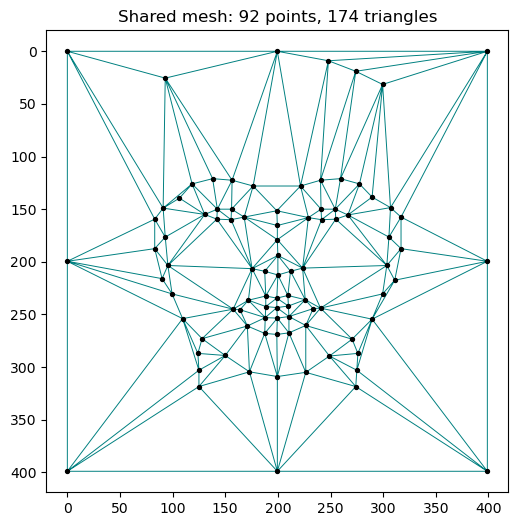

In [159]:
def triangulate(points, image_shape):
    h, w = image_shape[:2]
    subdiv = cv2.Subdiv2D((0, 0, w, h))
    for point in points:
        subdiv.insert(tuple(map(float, point)))
    triangles = []
    seen = set()
    for raw in subdiv.getTriangleList():
        vertices = raw.reshape(3, 2)
        if np.any(vertices < 0) or np.any(vertices[:, 0] >= w) or np.any(vertices[:, 1] >= h):
            continue
        distances = np.linalg.norm(vertices[:, None, :] - points[None, :, :], axis=2)
        indices = np.argmin(distances, axis=1)
        if np.max(distances[np.arange(3), indices]) > 0.1 or len(set(indices)) != 3:
            raise ValueError("Could not match a triangle to three distinct landmarks.")
        key = tuple(sorted(map(int, indices)))
        if key not in seen:
            seen.add(key)
            triangles.append(tuple(map(int, indices)))
    if not triangles:
        raise ValueError("No triangles found.")
    return triangles

midpoints = (points_a + points_b) / 2
triangles = triangulate(midpoints, image_a.shape)
fig, ax = plt.subplots(figsize=(6, 6))
ax.triplot(midpoints[:, 0], midpoints[:, 1], np.array(triangles), color="teal", linewidth=0.7)
ax.scatter(midpoints[:, 0], midpoints[:, 1], s=8, color="black")
ax.invert_yaxis()
ax.set_aspect("equal")
ax.set_title(f"Shared mesh: {len(midpoints)} points, {len(triangles)} triangles")
plt.show()


## 5. Move both faces to an intermediate shape
**Alpha (α)** is the mix control:
- **0:** face A.
- **0.5:** halfway between corresponding positions and colors.
- **1:** face B.

For each matching landmark, the target position is:

$$p_{target}=(1-\alpha)p_A+\alpha p_B$$

Each triangle from A and B is stretched, rotated, and shifted to the **same target triangle** using an affine transformation. Then its warped colors are combined:

$$I_{target}=(1-\alpha)I_{A,warped}+\alpha I_{B,warped}$$

The triangle mask controls *where* to paint; alpha controls the A/B mixture. Pixel interpolation during warping is separate from that mixture. The helper functions below implement those operations.


In [160]:
# Apply affine transform calculated using srcTri and dstTri to src and output an image of size.
def apply_affine_transform(src, srcTri, dstTri, size) :
    
    # Given a pair of triangles, find the affine transform.
    warpMat = cv2.getAffineTransform(np.float32(srcTri), np.float32(dstTri))
    
    # Apply the Affine Transform just found to the src image
    dst = cv2.warpAffine(src, warpMat, (size[0], size[1]), None, flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)

    return dst

# Warps and alpha blends triangular regions from img1 and img2 to img
def morph_triangle(img1, img2, img, t1, t2, t, alpha) :

    # Find bounding rectangle for each triangle
    r1 = cv2.boundingRect(np.float32([t1]))
    r2 = cv2.boundingRect(np.float32([t2]))
    r = cv2.boundingRect(np.float32([t]))

    # Offset points by left top corner of the respective rectangles
    t1Rect = []
    t2Rect = []
    tRect = []

    for i in range(0, 3):
        tRect.append(((t[i][0] - r[0]),(t[i][1] - r[1])))
        t1Rect.append(((t1[i][0] - r1[0]),(t1[i][1] - r1[1])))
        t2Rect.append(((t2[i][0] - r2[0]),(t2[i][1] - r2[1])))

    # Get mask by filling triangle
    mask = np.zeros((r[3], r[2], 3), dtype = np.float32)
    cv2.fillConvexPoly(mask, np.int32(tRect), (1.0, 1.0, 1.0), 16, 0)

    # Apply warpImage to small rectangular patches
    img1Rect = img1[r1[1]:r1[1] + r1[3], r1[0]:r1[0] + r1[2]]
    img2Rect = img2[r2[1]:r2[1] + r2[3], r2[0]:r2[0] + r2[2]]

    size = (r[2], r[3])
    warpImage1 = apply_affine_transform(img1Rect, t1Rect, tRect, size)
    warpImage2 = apply_affine_transform(img2Rect, t2Rect, tRect, size)

    # Alpha blend rectangular patches
    imgRect = (1.0 - alpha) * warpImage1 + alpha * warpImage2

    # Copy triangular region of the rectangular patch to the output image
    img[r[1]:r[1]+r[3], r[0]:r[0]+r[2]] = img[r[1]:r[1]+r[3], r[0]:r[0]+r[2]] * ( 1 - mask ) + imgRect * mask


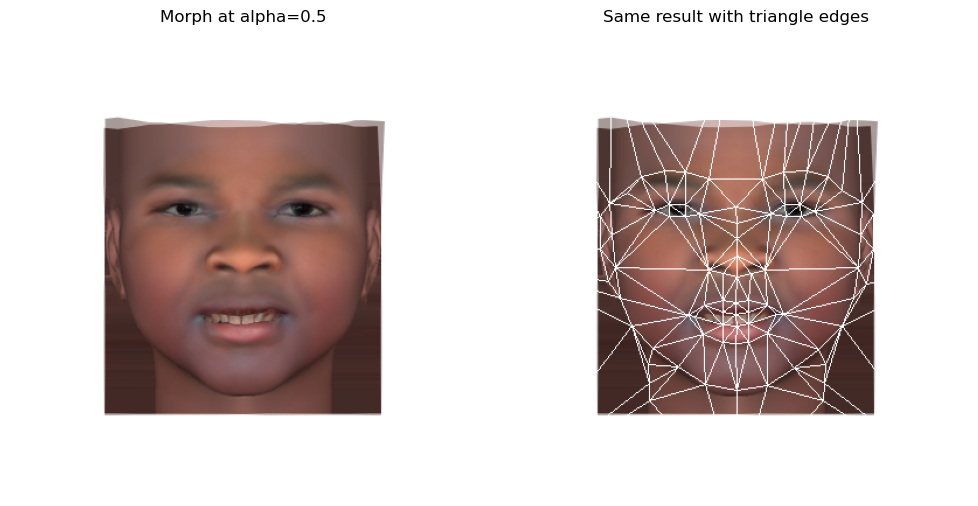

In [161]:
def morph_frame(alpha, show_mesh=False):
    if not 0 <= alpha <= 1:
        raise ValueError("alpha must be between 0 and 1")
    target = (1 - alpha) * points_a + alpha * points_b
    result = np.zeros_like(image_a, dtype=np.float32)
    a, b = image_a.astype(np.float32), image_b.astype(np.float32)
    for indices in triangles:
        idx = list(indices)
        morph_triangle(a, b, result, points_a[idx].tolist(),
                       points_b[idx].tolist(), target[idx].tolist(), alpha)
    result = np.clip(result, 0, 255).astype(np.uint8)
    if show_mesh:
        for indices in triangles:
            poly = np.rint(target[list(indices)]).astype(np.int32)
            cv2.polylines(result, [poly], True, (255, 255, 255), 1)
    return result

ALPHA = 0.5  # Change this value and rerun this cell to explore.
show_images([morph_frame(ALPHA), morph_frame(ALPHA, show_mesh=True)],
            [f"Morph at alpha={ALPHA}", "Same result with triangle edges"])


## 6. Why not just fade between the photographs?
A **cross-fade** mixes pixels at their original locations. If the eyes or mouths are in different positions, both can remain visible as ghosted features.

A **morph** first moves matching features toward a shared position, then mixes colors. Compare the eyes and mouth below.

Halfway in pixel coordinates does not necessarily mean halfway in perceived identity, emotion, or attractiveness.


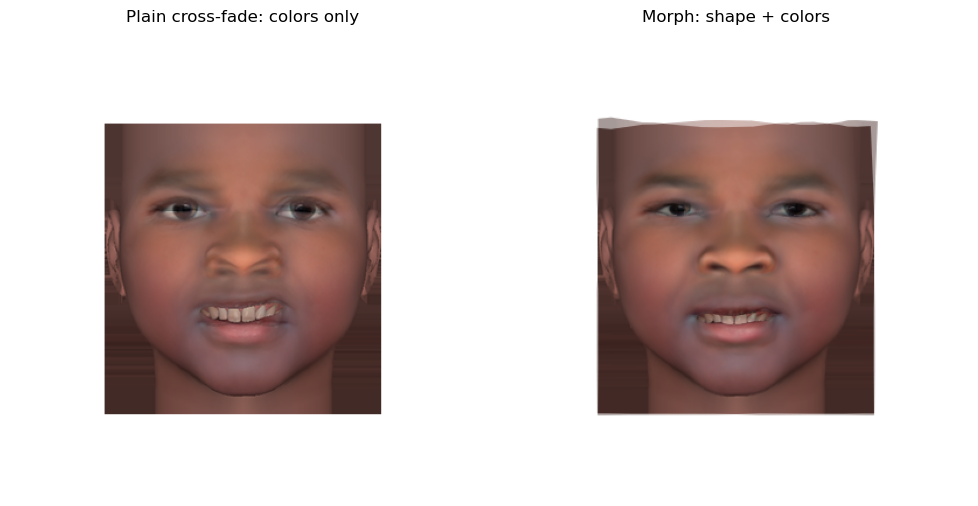

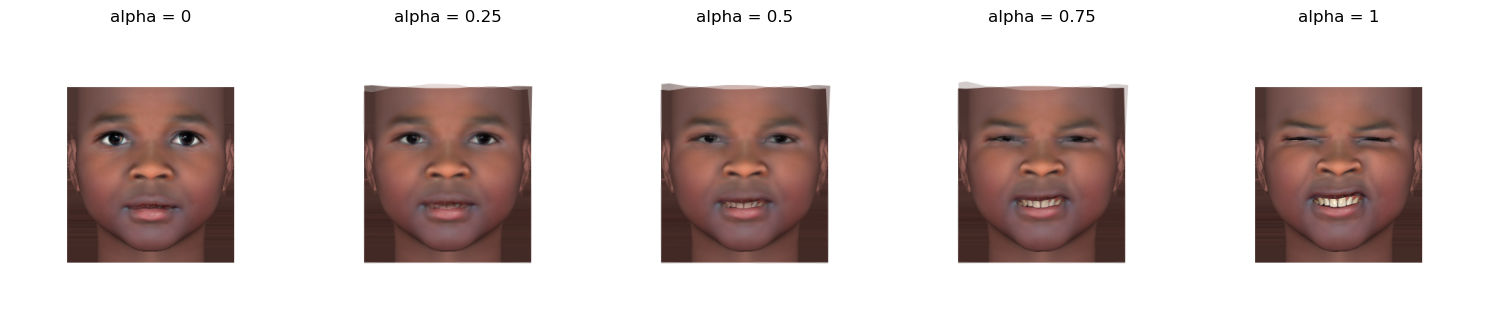

In [162]:
cross_fade = cv2.addWeighted(image_a, 0.5, image_b, 0.5, 0)
show_images([cross_fade, morph_frame(0.5)], ["Plain cross-fade: colors only", "Morph: shape + colors"])
alphas = [0, 0.25, 0.5, 0.75, 1]
show_images([morph_frame(a) for a in alphas], [f"alpha = {a}" for a in alphas], figsize=(15, 4))


## 7. Make a short animation
Repeat the same calculation while alpha moves from 0 to 1. More frames create smaller steps; frame duration controls playback speed.

The output filename is separate from the repository's original examples. GIFs have limited colors and time resolution, so they are convenient previews rather than lossless scientific image storage.


Saved: /Users/cyrusyang/Development/face-morphing-tutorial/output/face_morph_tutorial.gif


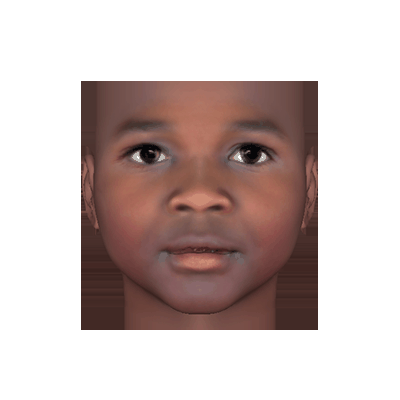

In [163]:
if FRAME_COUNT < 2 or FRAME_DURATION_MS <= 0:
    raise ValueError("Use at least two frames and a positive frame duration.")
frames = [Image.fromarray(cv2.cvtColor(morph_frame(float(a), SHOW_MESH_IN_GIF), cv2.COLOR_BGR2RGB))
          for a in np.linspace(0, 1, FRAME_COUNT)]
gif_path = OUTPUT_DIR / "face_morph_tutorial.gif"
frames[0].save(gif_path, save_all=True, append_images=frames[1:],
               duration=FRAME_DURATION_MS, loop=0)
print("Saved:", gif_path)
display(DisplayImage(filename=str(gif_path)))


## 8. Try it yourself and notice the limits
- Change `IMAGE_A` and `IMAGE_B`, then rerun from the top. 
- Change `ALPHA` to see how the balance changes.
- Set `SHOW_MESH_IN_GIF = True` to reveal the moving triangles.
- Compare a similarly posed pair with a more differently posed pair. Look for distortions near the face boundary, hair, mouth, and background.

**What this method does:** geometrically warp and blend two existing 2D pictures.

**What it does not guarantee:** a physically realistic face, preserved identity, neutral expression at the midpoint, or equal psychological changes for equal alpha steps. It does not infer an unseen 3D head. Extreme pose differences, occlusions, and inaccurate landmarks can produce artifacts.

For a family tutorial page, use the landmark picture, mesh picture, cross-fade comparison, and final animation as the four main illustrations. Keep the detailed helper code as an optional technical section.
